Author: Giovanni Squillero <[giovanni.squillero@polito.it](giovanni.squillero@polito.it)>  
Copyright © 2026 [Giovanni Squillero](https://squillero.github.io/) / [Politecnico di Torino](https://www.polito.it)  
[`https://github.com/squillero/computational-intelligence`](https://github.com/squillero/computational-intelligence)  
Free under certain conditions — see the [`license`](https://github.com/squillero/computational-intelligence/blob/master/LICENSE) for details.  

In [27]:
from random import random, choice, randint
from itertools import accumulate
import logging
from tqdm.auto import tqdm
from matplotlib import pyplot as plt
from icecream import ic

In [29]:
logging.getLogger().setLevel(logging.INFO)

In [63]:
NUM_OBJECTS = 10
MAX_WEIGHT = 100
VALUE = {o: random() * 10 for o in range(NUM_OBJECTS)}
WEIGHT = {o: random() * 10 for o in range(NUM_OBJECTS)}

In [12]:
# SOLUTION

solution = dict()

In [13]:
def fitness(solution: dict[int, int]) -> float:
    value = sum(n * VALUE[o] for o, n in solution.items())
    if sum(n * WEIGHT[o] for o, n in solution.items()) > MAX_WEIGHT:
        return 0.0
    else:
        return value

In [72]:
from hashlib import new


def tweak(solution: dict[int, int]) -> dict[int, int]:
    new_solution = dict(solution)
    while random() < 0.8:
        if random() < 0.5:
            o = randint(0, NUM_OBJECTS - 1)
            if o in new_solution:
                new_solution[o] += 1
            else:
                new_solution[o] = 1
        elif new_solution:
            o = choice(list(new_solution.keys()))
            new_solution[o] -= 1
            if new_solution[o] == 0:
                del new_solution[o]
    assert all(v > 0 for v in new_solution.values()), new_solution
    return new_solution

In [75]:
history = list()

best = max((object for object in range(NUM_OBJECTS)), key=lambda o: VALUE[o] / WEIGHT[o])
solution = {best: int(MAX_WEIGHT) // WEIGHT[best]}

steps = 0
history.append(fitness(solution))
no_improvements = 0

logging.info(fitness(solution))
while no_improvements < 10_000:
    steps += 1
    new_solution = tweak(solution)
    history.append(fitness(new_solution))
    if fitness(new_solution) > fitness(solution):
        solution = dict(new_solution)
        no_improvements = 0
    else:
        no_improvements += 1
logging.info(fitness(solution))

INFO:root:1062.661521540324
INFO:root:1062.661521540324


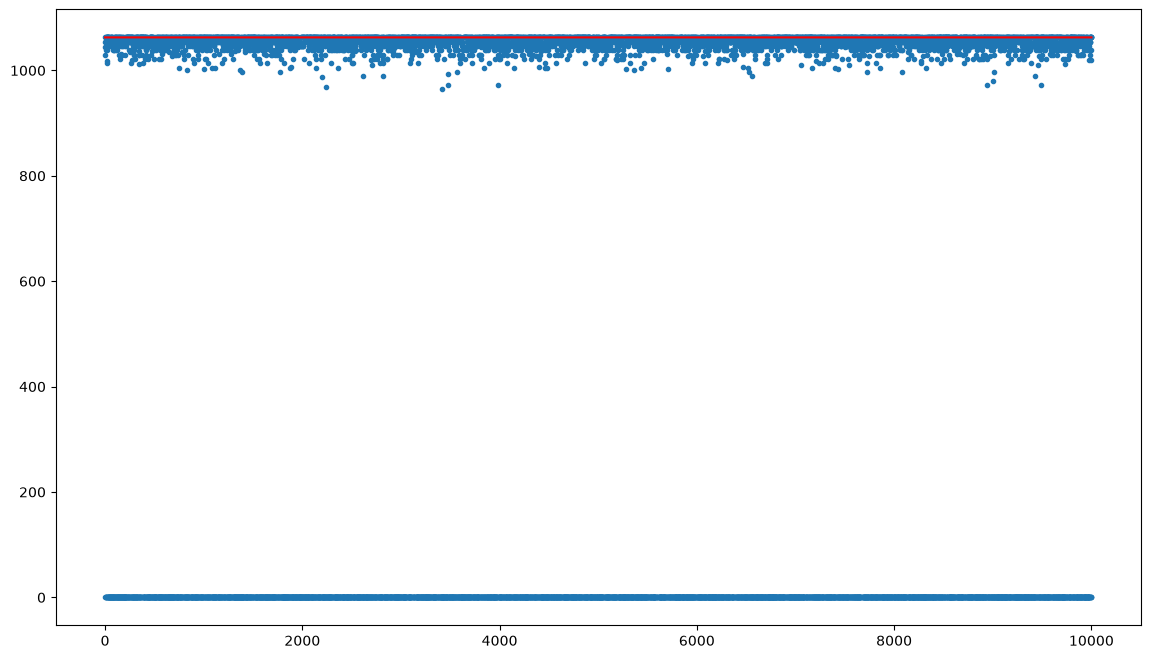

In [74]:
plt.figure(figsize=(14, 8))
plt.plot(
    range(len(history)),
    list(accumulate(history, max)),
    color="red",
)
_ = plt.scatter(range(len(history)), history, marker=".")

In [54]:
solution

{4: 130, 8: 31, 9: 88}